In [2]:
""" # Statistical Analysis and Visualization of Maize Production in Zambia

## Objectives
1. Collect and clean district-level maize production data.
2. Calculate descriptive statistics across districts and years.
3. Develop a multiple linear regression model predicting production from planted area and rainfall.
4. Visualize production patterns and model performance. """

' # Statistical Analysis and Visualization of Maize Production in Zambia\n\n## Objectives\n1. Collect and clean district-level maize production data.\n2. Calculate descriptive statistics across districts and years.\n3. Develop a multiple linear regression model predicting production from planted area and rainfall.\n4. Visualize production patterns and model performance. '

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

df = pd.read_csv("../data/maize_production.csv")
display(df.head())
display(df.describe().round(2))

,District,Year,Area_Hectares,Rainfall_mm,Production_Tonnes
0,Lusaka,2021,142.52,727.7,630.92
1,Lusaka,2022,131.72,961.2,658.25
2,Lusaka,2023,127.60,787.1,545.31
3,Lusaka,2024,148.49,954.5,680.27
4,Lusaka,2025,129.78,802.9,598.36


,Year,Area_Hectares,Rainfall_mm,Production_Tonnes
count,40.00,40.00,40.00,40.00
mean,2023.00,140.99,856.16,654.22
std,1.43,35.42,113.05,96.33
min,2021.00,86.35,614.60,476.61
25%,2022.00,115.51,786.28,581.21
50%,2023.00,131.56,848.30,633.03
75%,2024.00,166.46,936.18,710.70
max,2025.00,214.30,1155.60,929.47


District
Mumbwa     799.014
Chongwe    769.088
Kabwe      648.710
Petauke    632.380
Mkushi     631.660
Lusaka     622.622
Choma      572.170
Chipata    558.144
Name: Production_Tonnes, dtype: float64

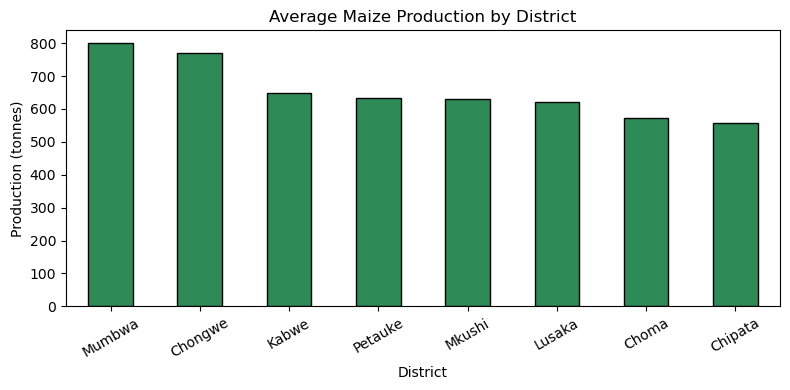

In [4]:
district_means = df.groupby("District")["Production_Tonnes"].mean().sort_values(ascending=False)
display(district_means)

district_means.plot(kind="bar", color="seagreen", edgecolor="black", figsize=(8, 4))
plt.title("Average Maize Production by District")
plt.ylabel("Production (tonnes)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Intercept: -59.21
Coefficients (Area, Rainfall): [2.849  0.3641]
R² Score: 0.9476
RMSE:     21.77 tonnes


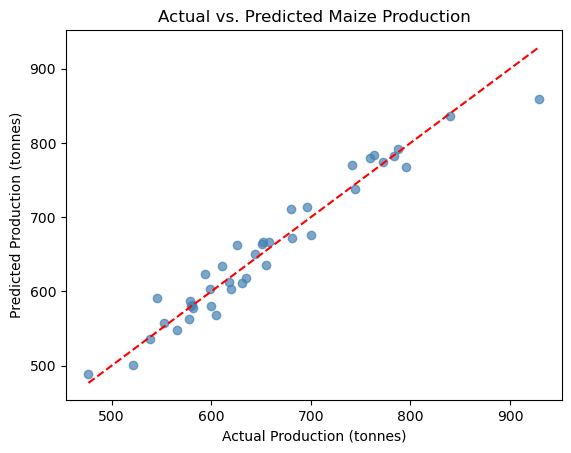

In [5]:
X = df[["Area_Hectares", "Rainfall_mm"]]
y = df["Production_Tonnes"]

model = LinearRegression().fit(X, y)
y_pred = model.predict(X)

print(f"Intercept: {model.intercept_:.2f}")
print(f"Coefficients (Area, Rainfall): {model.coef_.round(4)}")
print(f"R² Score: {r2_score(y, y_pred):.4f}")
print(f"RMSE:     {np.sqrt(mean_squared_error(y, y_pred)):.2f} tonnes")

plt.scatter(y, y_pred, color="steelblue", alpha=0.7)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual Production (tonnes)")
plt.ylabel("Predicted Production (tonnes)")
plt.title("Actual vs. Predicted Maize Production")
plt.show()

In [7]:
""" ## Findings & Recommendations
- Both planted area and annual rainfall have strong positive relationships with maize output.
- The multiple linear regression model achieves a high R² with low prediction error (RMSE), confirming it captures the main production drivers.
- Agricultural planners can use the accompanying Streamlit dashboard to monitor district performance and forecast yields under varying rainfall scenarios."""

' ## Findings & Recommendations\n- Both planted area and annual rainfall have strong positive relationships with maize output.\n- The multiple linear regression model achieves a high R² with low prediction error (RMSE), confirming it captures the main production drivers.\n- Agricultural planners can use the accompanying Streamlit dashboard to monitor district performance and forecast yields under varying rainfall scenarios.'